# Visualiszing CBX dynamics

In [77]:
%load_ext autoreload
%autoreload 2
import numpy as np
import cbx as cbx
from cbx.dynamics import CBO
from cbx.objectives import Rastrigin
from cbx.utils.objective_handling import cbx_objective_fh
from cbx.scheduler import effective_sample_size
from cbx.plotting import plot_dynamic, plot_dynamic_history

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [78]:
from cbx.utils.history import track
from cbx.dynamics import ParticleDynamic

class track_avg_energy(track):
    """
    Class for tracking of variable 'x' in the history dictionary.
    """
    @staticmethod
    def init_history(dyn: ParticleDynamic):
        dyn.history['avg_energy'] = []
    
    @staticmethod
    def update(dyn) -> None:
        """
        Update the history of the 'x' variable by copying the current particles to the next time step.

        Parameters
        ----------
            dyn : object
                The object to track in the history dictionary.

        Returns
        -------
            None
        """
        dyn.history['avg_energy'].append(np.mean(dyn.energy))

In [91]:
np.random.seed(420)

N = 100

conf = {'alpha': 10.0**15,
        'dt': 0.01,
        'sigma': 2.,
        'lamda': 1.,
        'batch_args':{
        'batch_size':200,
        'batch_partial': False},
        'd': 4,
        'max_it': 250,
        'N': N,
        'M': 1,
        'track_args': {'names':
                       ['update_norm', 
                        'energy','x', 
                        'consensus', 
                        'drift'],
                       "extra_tracks": [track_avg_energy]},
       }

## Using the plotting functions

....................
Starting Optimization with dynamic: CBO
....................
Time: 0.010, best current energy: [4.78966445]
Number of function evaluations: [200]
Time: 0.020, best current energy: [4.78966445]
Number of function evaluations: [300]
Time: 0.030, best current energy: [4.78966445]
Number of function evaluations: [400]
Time: 0.040, best current energy: [3.6165903]
Number of function evaluations: [500]
Time: 0.050, best current energy: [3.6165903]
Number of function evaluations: [600]
Time: 0.060, best current energy: [3.6165903]
Number of function evaluations: [700]
Time: 0.070, best current energy: [3.6165903]
Number of function evaluations: [800]
Time: 0.080, best current energy: [3.6165903]
Number of function evaluations: [900]
Time: 0.090, best current energy: [2.90171659]
Number of function evaluations: [1000]
Time: 0.100, best current energy: [1.98289808]
Number of function evaluations: [1100]
Time: 0.110, best current energy: [1.98289808]
Number of function evalu

array([[0.96598153, 0.97970743, 0.06532628, 0.08859652]])

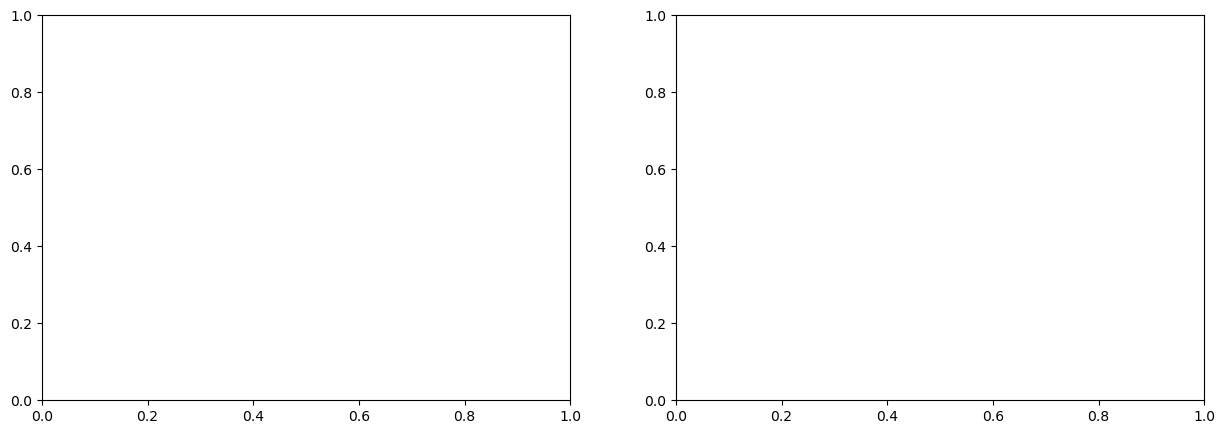

In [92]:
import matplotlib.pyplot as plt
from IPython import display

fig, ax = plt.subplots(1,2, figsize=(15,5))

f = Rastrigin()
x = cbx.utils.init_particles(shape=(conf['M'], conf['N'], conf['d']), x_min=-2.5, x_max = 5.) # Define the initial positions of the particles


dyn = CBO(f, x=x, noise='isotropic', f_dim='3D', **conf) # Define the CBO algorithm
sched = effective_sample_size(maximum=1e12)
# plotter = plot_dynamic(dyn, ax=ax[0],
#                        objective_args={'x_min':-3, 'x_max':3},
#                        plot_consensus=True,
#                        plot_drift=True)
# plotter.init_plot()
# while not dyn.terminate():
# for i in range(500):
#     dyn.step()
#     sched.update(dyn)
dyn.optimize(None, sched)
# update energy plot
    

In [90]:
dyn.history.keys()
dyn.history['avg_energy']

[15.748211587636302,
 16.854959181691775,
 18.347021157960953,
 18.925946497515127,
 21.192255138803763,
 24.911529248559813,
 27.142640816185317,
 27.24898833325096,
 29.638891869748132,
 35.00101419103862,
 36.42265252635325,
 38.78650077991637,
 42.11483969668688,
 43.187058040508546,
 48.333728037229314,
 52.74962710519205,
 56.555201839789646,
 59.460971230062434,
 66.54765993789754,
 72.20808282912749,
 73.92834653420415,
 85.28064068262469,
 99.03430126696821,
 93.90415436280314,
 110.6321876880511,
 124.33020138805054,
 141.8362994609771,
 148.89669692429626,
 169.91822986214953,
 160.24612043461389,
 177.8537233304032,
 169.25902666406347,
 207.99054308368787,
 234.04329406445984,
 267.5404799657753,
 303.6735454708288,
 289.4366178936337,
 336.2585916144126,
 348.4326818599878,
 351.8173726569236,
 391.27266735964855,
 426.69555141707207,
 504.39350392064733,
 621.6823316561754,
 756.6743702756993,
 720.7915809048831,
 760.7363569117807,
 877.9891207984672,
 1001.471432111098

In [72]:
import numpy as np
from math import log10

# Save a list
l = [e[0] for e in dyn.history['energy']]
np.save(f'energy_history_d{conf["d"]}_N{conf["N"]}_M{conf["M"]}_dt{str(conf["dt"]).replace(".", "")}_alpha_10_{int(log10(conf["alpha"]))}.npy', l)

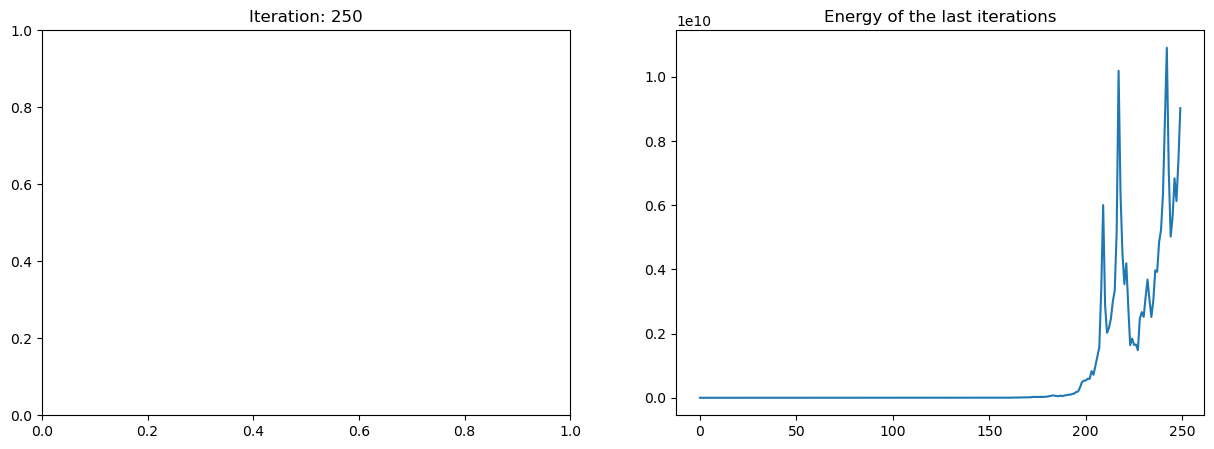

In [94]:
ax[1].clear()
max_iter = int(2.5 / conf['dt'])
results = np.array([e[0] for e in dyn.history['avg_energy'][:max_iter]])/(2*conf["N"])
ax[1].plot(results/(results[0]))
ax[1].set_title('Energy of the last iterations') 
ax[0].set_title('Iteration: ' + str(dyn.it)) 
# plotter.update(wait=0.2)
display.display(fig)
display.clear_output(wait=True)

In [ ]:
import matplotlib.pyplot as plt
plt.close('all')
plotter = plot_dynamic_history(
            dyn, dims=[0,1], 
            objective_args={'x_min':-3, 'x_max':3, 'cmap':'viridis',
                            'num_pts':300},
            particle_args = {'s':50, 'c':'xkcd:sky', 'marker':'o'},
            drift_args = {'color':'pink', 'width':0.003},
            plot_consensus=True,
            plot_drift=True)
plotter.run_plots(wait=0.5, freq=1,)